# P0 · Boiling point: zero-shot prompt

This notebook predicts a molecule's normal boiling point (K) from its SMILES string.

**Plan**
1. Load and clean the NIST-derived data (units, invalid SMILES, duplicates, conflicts).
2. Split *unique molecules* 80/10/10 (train/validation/test, seed 42).
3. Build chemically motivated features from SMILES only.
4. Compare a median baseline with a few models, including a chemistry-informed idea
   (a **Joback group-contribution estimate** used as a feature and as a physics baseline for Δ-learning).
5. Pick the final model on **validation** only, then score the **test** set once.
6. Save the model, metrics and figures, and provide `predict_boiling_point(smiles)`.

In [1]:
import json, time, warnings
from pathlib import Path

import joblib
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from rdkit import Chem, RDLogger
from rdkit.Chem import Descriptors, rdFingerprintGenerator
from sklearn.ensemble import HistGradientBoostingRegressor, RandomForestRegressor
from sklearn.impute import SimpleImputer
from sklearn.linear_model import RidgeCV
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
from sklearn.model_selection import train_test_split
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler

RDLogger.DisableLog("rdApp.*")
warnings.filterwarnings("ignore", category=RuntimeWarning)
SEED = 42
np.random.seed(SEED)
T0 = time.time()

# Locate the boiling-point module root (works from prompt_test/ or the module root).
MODULE = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "data" / "CompoundData.parquet").exists())
OUT = MODULE / "outputs" / "prompt_test_P0"
OUT.mkdir(parents=True, exist_ok=True)
print("Module root:", MODULE.name, "| outputs ->", OUT.relative_to(MODULE))

Module root: 01_boiling_point | outputs -> outputs/prompt_test_P0


## 1. Load the data

In [2]:
nist_file = MODULE / "outputs" / "nist_acquisition" / "NIST_BP_SMILES.parquet"
DATA_FILE = nist_file if nist_file.exists() else MODULE / "data" / "CompoundData.parquet"
print("Using:", DATA_FILE.relative_to(MODULE))

raw = pd.read_parquet(DATA_FILE)
print(raw.shape)
print(raw[["CAS", "SMILES", "BP"]].head())
raw["BP"].describe().round(1)

Using: data/CompoundData.parquet
(3541, 5)
        CAS                SMILES     BP
0  999-90-6       CC(=O)SC(C)(C)C  405.0
1   99-98-9   CN(C)C1=CC=C(C=C1)N  536.2
2  999-78-0          CC#CC(C)(C)C  356.0
3   99-97-8   CC1=CC=C(C=C1)N(C)C  484.2
4   99-94-5  CC1=CC=C(C=C1)C(=O)O  547.7


count    3541.0
mean      457.3
std        71.0
min        29.9
25%       409.6
50%       453.2
75%       504.2
max       721.2
Name: BP, dtype: float64

**Units check.** BP spans ~30–720 K with a median of ~453 K, consistent with kelvin for
typical organic liquids. Only `SMILES` (input) and `BP` (target) are used from here on.

## 2. Clean the data

Steps, each recorded in a cleaning log:
- drop missing or unparsable SMILES and multi-component entries (salts/mixtures);
- canonicalize SMILES **without stereochemistry** — our 2D features cannot tell stereoisomers apart,
  so they are treated as one molecule (this also prevents near-identical molecules leaking across splits);
- drop physically implausible low values: a molecule with ≥ 5 heavy atoms (C, N, O, S, Cl) boiling
  below 250 K is almost certainly a °C value or a reduced-pressure entry (e.g. 2-methylbutylamine listed at 96.5 "K"
  boils at 96.5 °C);
- merge duplicates: keep the median if replicate measurements agree within 10 K, otherwise drop the molecule as conflicting.

In [3]:
log = []
def record(step, before, after, note):
    log.append({"step": step, "removed": before - after, "remaining": after, "note": note})

df = raw[["SMILES", "BP"]].copy()
n0 = len(df)
record("start", n0, n0, f"rows in {DATA_FILE.name}")

df = df.dropna(subset=["SMILES", "BP"])
record("missing SMILES/BP", n0, len(df), "no structure or no target")

df["mol"] = df["SMILES"].map(Chem.MolFromSmiles)
n = len(df); df = df[df["mol"].notna()]
record("invalid SMILES", n, len(df), "RDKit could not parse")

df["canon"] = df["mol"].map(lambda m: Chem.MolToSmiles(m, isomericSmiles=False))
n = len(df); df = df[~df["canon"].str.contains(".", regex=False)]
record("multi-component", n, len(df), "salts/mixtures")

df["heavy_atoms"] = df["mol"].map(lambda m: m.GetNumHeavyAtoms())
implausible = (df["heavy_atoms"] >= 5) & (df["BP"] < 250)
removed_implausible = df.loc[implausible, ["canon", "BP"]]
n = len(df); df = df[~implausible]
record("implausibly low BP", n, len(df), "likely °C or reduced-pressure entries")

g = df.groupby("canon")["BP"].agg(["median", "min", "max", "count"])
conflict = g.index[(g["max"] - g["min"]) > 10]
n_dup_rows = int((g["count"] > 1).sum())
n = len(df); df = df[~df["canon"].isin(conflict)]
record("conflicting duplicates", n, len(df), f"all rows of {len(conflict)} molecules whose replicates differ by > 10 K")

clean = df.groupby("canon", as_index=False)["BP"].median()
record("merge duplicates", len(df), len(clean), "median of agreeing replicates")

cleaning_log = pd.DataFrame(log)
print("Removed as implausibly low:"); print(removed_implausible.to_string())
cleaning_log

Removed as implausibly low:
                   canon     BP
1483   CCC(OC(C)C)OC(C)C  146.5
1736            CCC(C)CN   96.5
1823   CC(C)CC(=O)OC(C)C  141.8
1841  CCCCCC(=O)C=CC(C)C  223.5
3272    CCCCOC(=O)CC(C)C  175.7


,step,removed,remaining,note
0,start,0,3541,rows in CompoundData.parquet
1,missing SMILES/BP,229,3312,no structure or no target
2,invalid SMILES,0,3312,RDKit could not parse
3,multi-component,0,3312,salts/mixtures
4,implausibly low BP,5,3307,likely °C or reduced-pressure entries
5,conflicting duplicates,26,3281,all rows of 11 molecules whose replicates diff...
6,merge duplicates,91,3190,median of agreeing replicates


## 3. Split unique molecules (80/10/10, seed 42)

In [4]:
train_df, temp_df = train_test_split(clean, test_size=0.2, random_state=SEED)
val_df, test_df = train_test_split(temp_df, test_size=0.5, random_state=SEED)
assert not (set(train_df.canon) & set(val_df.canon) or set(train_df.canon) & set(test_df.canon)
            or set(val_df.canon) & set(test_df.canon))
for name, d in [("train", train_df), ("validation", val_df), ("test", test_df)]:
    print(f"{name:>10}: {len(d):5d} molecules, BP median {d.BP.median():.0f} K")

     train:  2552 molecules, BP median 459 K
validation:   319 molecules, BP median 462 K
      test:   319 molecules, BP median 460 K


## 4. Chemically motivated features

Boiling point reflects the strength of intermolecular forces that must be overcome:
- **Size / dispersion**: molecular weight, heavy-atom count, molar refractivity (`MolMR`, a polarizability proxy),
  surface-area descriptors (`LabuteASA`, VSA bins).
- **Shape**: branching lowers BP (less contact area) — captured by connectivity/shape indices (Chi, Kappa).
- **Polarity and hydrogen bonding**: H-bond donors/acceptors, TPSA, partial charges, and functional-group
  counts (`fr_*`), e.g. alcohols and acids boil far higher than isomeric ethers.
- **Substructure fingerprint** (Morgan counts, radius 2): local atom environments for anything the descriptors miss.

**Creative, chemistry-informed idea — Joback group contributions.** Joback & Reid (1987) estimate
$T_b = 198\,\text{K} + \sum_i n_i\,\Delta T_{b,i}$ from functional-group counts. We implement it with SMARTS
patterns and test two ways to use it: (a) as an extra feature, and (b) **Δ-learning**, where the model
learns only the *correction* `BP − Joback`. Joback is known to over-predict for large molecules, so the ML model may
learn that systematic correction. We keep it only if validation error improves.

In [5]:
# (name, SMARTS, Tb contribution in K) -- Joback & Reid (1987). Ordered from most to least specific;
# each heavy atom is claimed by the first group that matches it.
JOBACK_GROUPS = [
    ("COOH",          "[CX3](=O)[OX2H1]",            169.09),
    ("ester -COO-",   "[CX3](=O)[OX2;$(O[#6])]",          81.10),
    ("aldehyde",      "[CX3H1](=O)",                 72.24),
    ("ketone ring",   "[CX3;R;$(C([#6])[#6])]=O",         94.97),
    ("ketone",        "[CX3;!R;$(C([#6])[#6])]=O",        76.75),
    ("nitro",         "[N+](=O)[O-]",                152.54),
    ("nitrile",       "C#N",                         125.66),
    ("OH phenol",     "[OX2H1;$(Oc)]",                  76.34),
    ("OH alcohol",    "[OX2H1]",                     92.88),
    ("=O other",      "[OX1]=*",                     -10.50),
    ("NH2",           "[NX3H2]",                     73.23),
    ("NH ring",       "[N,n;H1;R]",                  52.82),
    ("NH",            "[NX3H1;!R]",                  50.17),
    ("N< ring",       "[NX3H0;R]",                   52.82),   # Joback ring >N- not tabulated for Tb; use ring >NH
    ("N<",            "[NX3H0;!R]",                  11.74),
    ("=N- ring",      "[n,N;R;X2]",                  57.55),
    ("=N-",           "[NX2;!R]",                    74.60),
    ("SH",            "[SX2H1]",                     63.56),
    ("-S- ring",      "[s,S;R]",                     52.10),
    ("-S-",           "[S;!R]",                      68.78),
    ("-O- ring",      "[o,O;R]",                     31.22),
    ("-O-",           "[O;!R]",                      22.42),
    ("F",             "[F]",                         -0.03),
    ("Cl",            "[Cl]",                        38.13),
    ("Br",            "[Br]",                        66.86),
    ("I",             "[I]",                         93.84),
    ("=C= ",          "[CX2](=*)=*",                 26.15),
    ("#CH",           "[CX2H1]#*",                   9.20),
    ("#C-",           "[CX2H0]#*",                   27.38),
    ("ring =CH-",     "[c,C;R;H1;$(*=*),$([c])]",    26.73),
    ("ring =C<",      "[c,C;R;H0;$(*=*),$([c])]",    31.01),
    ("=CH2",          "[CX3H2]=*",                   18.18),
    ("=CH-",          "[CX3H1;!R]=*",                24.96),
    ("=C<",           "[CX3H0;!R]=*",                24.14),
    ("ring CH2",      "[CX4H2;R]",                   27.15),
    ("ring CH",       "[CX4H1;R]",                   21.78),
    ("ring C",        "[CX4H0;R]",                   21.32),
    ("CH3",           "[CX4H3]",                     23.58),
    ("CH2",           "[CX4H2]",                     22.88),
    ("CH",            "[CX4H1]",                     21.74),
    ("C",             "[CX4H0]",                     18.25),
]
_PATTERNS = [(n, Chem.MolFromSmarts(s), v) for n, s, v in JOBACK_GROUPS]
assert all(p is not None for _, p, _ in _PATTERNS)


def joback_tb(mol):
    """Return (Joback Tb estimate in K, fraction of heavy atoms not assigned to any group)."""
    claimed = set()
    total = 198.0
    for _, patt, value in _PATTERNS:
        for match in mol.GetSubstructMatches(patt):
            if claimed.intersection(match):
                continue
            claimed.update(match)
            total += value
    n = mol.GetNumHeavyAtoms()
    return total, (n - len(claimed)) / n

In [6]:
DESC_NAMES = [n for n, _ in Descriptors.descList if n != "Ipc"]  # Ipc overflows for larger molecules
MORGAN = rdFingerprintGenerator.GetMorganGenerator(radius=2, fpSize=1024)

def featurize(mols):
    """Return a DataFrame of RDKit descriptors, Joback estimate, and Morgan count bits."""
    rows = []
    for m in mols:
        d = Descriptors.CalcMolDescriptors(m)
        feats = {k: d[k] for k in DESC_NAMES}
        feats["joback_tb"], feats["joback_unassigned"] = joback_tb(m)
        rows.append(feats)
    X = pd.DataFrame(rows).astype(float).replace([np.inf, -np.inf], np.nan)
    fp = np.array([MORGAN.GetCountFingerprintAsNumPy(m) for m in mols], dtype=float)
    fp = pd.DataFrame(fp, columns=[f"mfp_{i}" for i in range(fp.shape[1])])
    return pd.concat([X, fp], axis=1)

t = time.time()
feats = {name: featurize([Chem.MolFromSmiles(s) for s in d.canon])
         for name, d in [("train", train_df), ("val", val_df), ("test", test_df)]}
y = {"train": train_df.BP.values, "val": val_df.BP.values, "test": test_df.BP.values}
print(f"Featurized in {time.time() - t:.0f} s; feature matrix", feats["train"].shape)

jb_train = feats["train"]["joback_tb"]
print(f"Joback alone on TRAIN: MAE {mean_absolute_error(y['train'], jb_train):.1f} K, "
      f"r = {np.corrcoef(y['train'], jb_train)[0, 1]:.3f}")

Featurized in 10 s; feature matrix (2552, 1235)
Joback alone on TRAIN: MAE 31.4 K, r = 0.845


### Feature sets
- `desc`: RDKit 2D descriptors (~210)
- `desc+joback`: descriptors plus the Joback estimate
- `desc+morgan`: descriptors plus 1024 Morgan count bits
- `desc+joback+morgan`: everything

In [7]:
DESC = DESC_NAMES
JB = ["joback_tb", "joback_unassigned"]
MFP = [c for c in feats["train"].columns if c.startswith("mfp_")]
FEATURE_SETS = {"desc": DESC, "desc+joback": DESC + JB, "desc+morgan": DESC + MFP,
                "desc+joback+morgan": DESC + JB + MFP}

## 5. Compare models on the validation set

All scalers, imputers and early-stopping splits are fitted on **training data only**.
- **Baseline**: always predict the training median.
- **Ridge** (linear, scaled descriptors; `RidgeCV` chooses α by internal CV on train).
- **Random forest** and **histogram gradient boosting (HGB)** — nonlinear tree ensembles that handle mixed-scale
  features without scaling.
- **Δ-learning**: HGB predicts `BP − Joback`, then we add Joback back.

In [8]:
def metrics(y_true, y_pred):
    return {"MAE": mean_absolute_error(y_true, y_pred),
            "RMSE": float(np.sqrt(mean_squared_error(y_true, y_pred))),
            "R2": r2_score(y_true, y_pred)}

def hgb(**kw):
    params = dict(max_iter=2000, learning_rate=0.05, max_leaf_nodes=31, min_samples_leaf=10,
                  l2_regularization=1.0, early_stopping=True, validation_fraction=0.1,
                  n_iter_no_change=50, random_state=SEED)
    params.update(kw)
    return HistGradientBoostingRegressor(**params)

class DeltaModel:
    """Learn the residual BP - Joback, then add the Joback estimate back."""
    def __init__(self, model): self.model = model
    def fit(self, X, y):
        self.model.fit(X, y - X["joback_tb"].values); return self
    def predict(self, X):
        return self.model.predict(X) + X["joback_tb"].values

CANDIDATES = {
    "Ridge | desc":                (DESC, lambda: make_pipeline(SimpleImputer(strategy="median"), StandardScaler(),
                                                                RidgeCV(alphas=np.logspace(-2, 3, 12)))),
    "RandomForest | desc":         (DESC, lambda: RandomForestRegressor(n_estimators=400, min_samples_leaf=2,
                                                                         max_features=0.33, n_jobs=4, random_state=SEED)),
    "HGB | desc":                  (DESC, hgb),
    "HGB | desc+morgan":           (FEATURE_SETS["desc+morgan"], hgb),
    "HGB | desc+joback":           (FEATURE_SETS["desc+joback"], hgb),
    "HGB-Δ(Joback) | desc+joback": (FEATURE_SETS["desc+joback"], lambda: DeltaModel(hgb())),
    "HGB-Δ(Joback) | all":         (FEATURE_SETS["desc+joback+morgan"], lambda: DeltaModel(hgb())),
}

median_bp = float(np.median(y["train"]))
results = [{"model": "Baseline (train median)", **metrics(y["val"], np.full(len(y["val"]), median_bp))}]
fitted = {}
for name, (cols, make) in CANDIDATES.items():
    t = time.time()
    model = make().fit(feats["train"][cols], y["train"])
    fitted[name] = (cols, model)
    results.append({"model": name, **metrics(y["val"], model.predict(feats["val"][cols])),
                    "fit_s": round(time.time() - t, 1)})

val_results = pd.DataFrame(results).set_index("model").sort_values("MAE")
val_results.round(2)

,MAE,RMSE,R2,fit_s
model,,,,
HGB | desc+morgan,12.42,21.01,0.90,4.0
HGB-Δ(Joback) | desc+joback,12.54,22.64,0.89,0.9
HGB | desc,12.76,22.10,0.89,1.4
HGB-Δ(Joback) | all,12.78,22.87,0.89,3.1
HGB | desc+joback,13.01,22.21,0.89,1.1
RandomForest | desc,13.89,22.88,0.89,3.4
Ridge | desc,14.61,23.84,0.88,0.2
Baseline (train median),55.84,67.95,-0.00,NaN


### Small hyper-parameter check (validation only)
We tune the learning rate and tree size of the best-performing HGB variant on a tiny grid,
still scoring only on validation.

In [9]:
best_hgb = next(n for n in val_results.index if n.startswith("HGB"))
cols, base = fitted[best_hgb]
is_delta = isinstance(base, DeltaModel)
grid = []
for lr in (0.03, 0.1):
    for leaves in (15, 63):
        m = hgb(learning_rate=lr, max_leaf_nodes=leaves)
        m = (DeltaModel(m) if is_delta else m).fit(feats["train"][cols], y["train"])
        name = f"{best_hgb} (lr={lr}, leaves={leaves})"
        fitted[name] = (cols, m)
        grid.append({"model": name, **metrics(y["val"], m.predict(feats["val"][cols]))})
val_results = pd.concat([val_results, pd.DataFrame(grid).set_index("model")]).sort_values("MAE")
val_results.round(2)

,MAE,RMSE,R2,fit_s
model,,,,
HGB | desc+morgan,12.42,21.01,0.90,4.0
"HGB | desc+morgan (lr=0.03, leaves=15)",12.48,21.41,0.90,NaN
HGB-Δ(Joback) | desc+joback,12.54,22.64,0.89,0.9
HGB | desc,12.76,22.10,0.89,1.4
HGB-Δ(Joback) | all,12.78,22.87,0.89,3.1
"HGB | desc+morgan (lr=0.1, leaves=63)",12.88,21.74,0.90,NaN
"HGB | desc+morgan (lr=0.1, leaves=15)",12.89,21.42,0.90,NaN
HGB | desc+joback,13.01,22.21,0.89,1.1
"HGB | desc+morgan (lr=0.03, leaves=63)",13.04,22.32,0.89,NaN


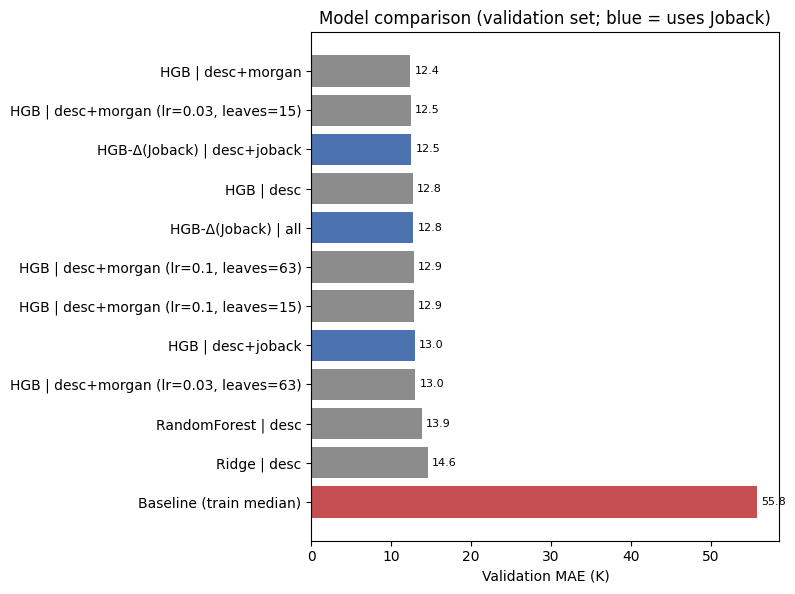

In [10]:
fig, ax = plt.subplots(figsize=(8, 0.42 * len(val_results) + 1))
v = val_results.sort_values("MAE", ascending=False)
colors = ["#c44e52" if "Baseline" in n else "#4c72b0" if ("joback" in n.lower()) else "#8c8c8c" for n in v.index]
ax.barh(v.index, v["MAE"], color=colors)
for i, val in enumerate(v["MAE"]):
    ax.text(val + 0.5, i, f"{val:.1f}", va="center", fontsize=8)
ax.set_xlabel("Validation MAE (K)"); ax.set_title("Model comparison (validation set; blue = uses Joback)")
fig.tight_layout(); fig.savefig(OUT / "validation_comparison.png", dpi=150); plt.show()

### Choose the final model (validation only)
Rule: the lowest validation MAE wins, **unless** a simpler model is within 1 K, in which case we take the simpler
one (fewer features / no Δ-wrapper). The model is then frozen.

In [11]:
def complexity(name):
    return (("morgan" in name) or ("all" in name)) + ("Δ" in name) + ("lr=" in name)

best_mae = val_results.drop("Baseline (train median)")["MAE"].min()
near_best = val_results[(val_results["MAE"] <= best_mae + 1.0) & ~val_results.index.str.startswith("Baseline")]
FINAL_NAME = min(near_best.index, key=lambda n: (complexity(n), near_best.loc[n, "MAE"]))
FINAL_COLS, FINAL_MODEL = fitted[FINAL_NAME]
print("Best validation MAE: %.2f K" % best_mae)
print("Final model:", FINAL_NAME, "| validation MAE %.2f K" % val_results.loc[FINAL_NAME, "MAE"])

joback_val = mean_absolute_error(y["val"], feats["val"]["joback_tb"])
print(f"Does the Joback idea help? Joback alone val MAE {joback_val:.1f} K; "
      f"HGB desc {val_results.loc['HGB | desc', 'MAE']:.2f} K vs "
      f"HGB desc+joback {val_results.loc['HGB | desc+joback', 'MAE']:.2f} K vs "
      f"Δ-learning {val_results.loc['HGB-Δ(Joback) | desc+joback', 'MAE']:.2f} K")

Best validation MAE: 12.42 K
Final model: HGB | desc | validation MAE 12.76 K
Does the Joback idea help? Joback alone val MAE 31.5 K; HGB desc 12.76 K vs HGB desc+joback 13.01 K vs Δ-learning 12.54 K


**Are these differences real?** A paired bootstrap over validation molecules (2000 resamples) gives a 95% interval
for each model's MAE minus the chosen model's MAE. Intervals spanning 0 mean the validation set cannot tell them apart.

In [12]:
rng = np.random.default_rng(SEED)
idx = rng.integers(0, len(y["val"]), size=(2000, len(y["val"])))
err_final = np.abs(FINAL_MODEL.predict(feats["val"][FINAL_COLS]) - y["val"])
rows = []
for name in [n for n in val_results.index if not n.startswith("Baseline") and "lr=" not in n]:
    c, mdl = fitted[name]
    diff = (np.abs(mdl.predict(feats["val"][c]) - y["val"]) - err_final)[idx].mean(axis=1)
    rows.append({"model": name, "ΔMAE vs final (K)": diff.mean(),
                 "95% CI low": np.percentile(diff, 2.5), "95% CI high": np.percentile(diff, 97.5)})
pd.DataFrame(rows).set_index("model").round(2)

,ΔMAE vs final (K),95% CI low,95% CI high
model,,,
HGB | desc+morgan,-0.35,-0.90,0.15
HGB-Δ(Joback) | desc+joback,-0.24,-1.47,1.12
HGB | desc,0.00,0.00,0.00
HGB-Δ(Joback) | all,0.00,-1.20,1.39
HGB | desc+joback,0.24,-0.71,1.24
RandomForest | desc,1.11,0.20,2.05
Ridge | desc,1.83,0.13,3.52


## 6. Final evaluation on the held-out test set (run once)

In [13]:
pred_test = FINAL_MODEL.predict(feats["test"][FINAL_COLS])
test_metrics = {"final_model": metrics(y["test"], pred_test),
                "baseline_median": metrics(y["test"], np.full(len(y["test"]), median_bp))}
pd.DataFrame(test_metrics).T.round(2)

,MAE,RMSE,R2
final_model,14.78,26.60,0.89
baseline_median,62.42,80.29,-0.00


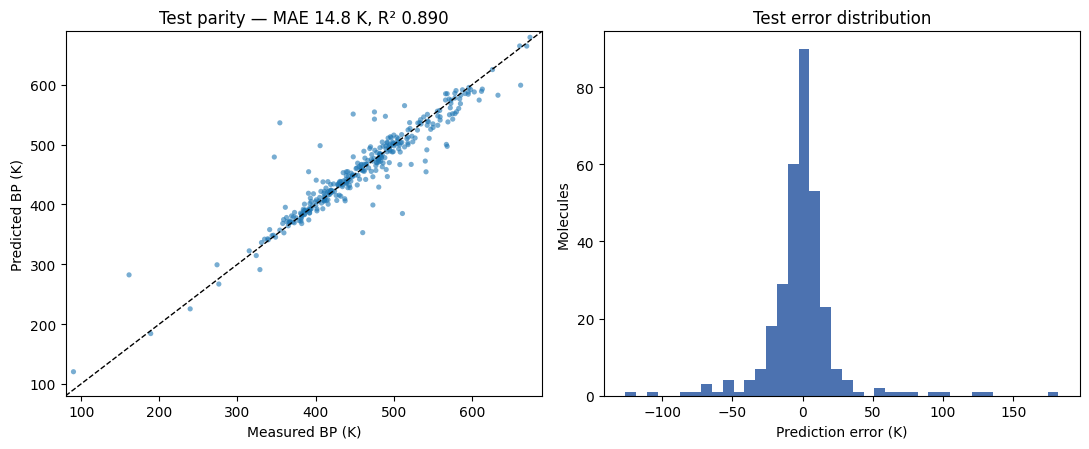

In [14]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4.6))
ax = axes[0]
lo, hi = min(y["test"].min(), pred_test.min()) - 10, max(y["test"].max(), pred_test.max()) + 10
ax.scatter(y["test"], pred_test, s=14, alpha=0.6, edgecolor="none")
ax.plot([lo, hi], [lo, hi], "k--", lw=1)
m = test_metrics["final_model"]
ax.set(xlim=(lo, hi), ylim=(lo, hi), xlabel="Measured BP (K)", ylabel="Predicted BP (K)",
       title=f"Test parity — MAE {m['MAE']:.1f} K, R² {m['R2']:.3f}")
axes[1].hist(pred_test - y["test"], bins=40, color="#4c72b0")
axes[1].set(xlabel="Prediction error (K)", ylabel="Molecules", title="Test error distribution")
fig.tight_layout(); fig.savefig(OUT / "test_parity.png", dpi=150); plt.show()

In [15]:
errors = test_df[["canon", "BP"]].rename(columns={"canon": "SMILES", "BP": "measured_K"}).copy()
errors["predicted_K"] = pred_test.round(1)
errors["joback_K"] = feats["test"]["joback_tb"].values.round(1)
errors["error_K"] = (errors.predicted_K - errors.measured_K).round(1)
largest = errors.reindex(errors.error_K.abs().sort_values(ascending=False).index).head(8)
largest

,SMILES,measured_K,predicted_K,joback_K,error_K
468,CC(=O)OC1CC(=O)N1,354.2,536.4,393.9,182.2
785,CC(CO)C(C)(C)O,347.1,479.2,517.4,132.1
2405,CS(C)(=O)=O,511.0,384.8,257.1,-126.2
2990,O=[O+][O-],161.3,282.2,209.9,120.9
2171,CN(C)[N+](=O)[O-],460.2,352.9,409.4,-107.3
1626,CCCCCCCCCCCC(=O)OCC,448.0,551.1,577.9,103.1
2057,CCOc1ccc(-c2noc(CCC(=O)O)n2)cc1,405.7,498.2,859.0,92.5
2144,CCc1ncc[nH]1,541.2,454.5,439.3,-86.7


**Reading the largest errors.** Check whether each worst case is a model failure or a data problem:
entries where the "measured" value is far below both the model *and* the independent Joback estimate
often look like reduced-pressure or mis-entered values that our cleaning rule did not catch.

## 7. Save the model, metrics and figures

In [16]:
artifact = {"model": FINAL_MODEL, "feature_columns": FINAL_COLS, "model_name": FINAL_NAME,
            "train_elements": sorted({a.GetSymbol() for s in train_df.canon for a in Chem.MolFromSmiles(s).GetAtoms()}),
            "train_bp_range_K": [float(y["train"].min()), float(y["train"].max())],
            "train_heavy_atom_range": [int(feats["train"]["HeavyAtomCount"].min()),
                                       int(feats["train"]["HeavyAtomCount"].max())]}
joblib.dump(artifact, OUT / "bp_model.joblib")
summary = {"data_file": str(DATA_FILE.relative_to(MODULE)), "seed": SEED,
           "n_molecules": {"train": len(train_df), "val": len(val_df), "test": len(test_df)},
           "final_model": FINAL_NAME, "validation": val_results.round(3).reset_index().to_dict("records"),
           "test": test_metrics}
(OUT / "metrics.json").write_text(json.dumps(summary, indent=2, default=float))
cleaning_log.to_csv(OUT / "cleaning_log.csv", index=False)
val_results.to_csv(OUT / "validation_results.csv")
errors.to_csv(OUT / "test_predictions.csv", index=False)
print(sorted(p.name for p in OUT.iterdir()))

['bp_model.joblib', 'cleaning_log.csv', 'metrics.json', 'test_parity.png', 'test_predictions.csv', 'validation_comparison.png', 'validation_results.csv']


## 8. `predict_boiling_point(smiles)`
Accepts one SMILES string or a list. Invalid SMILES raise a clear `ValueError`; molecules outside the training
domain (new elements or unusual size) are still predicted but flagged with a warning.

In [17]:
def predict_boiling_point(smiles, artifact_path=OUT / "bp_model.joblib"):
    """Predict normal boiling point(s) in kelvin from SMILES. Returns a float for one SMILES, else an array."""
    single = isinstance(smiles, str)
    items = [smiles] if single else list(smiles)
    if not items:
        raise ValueError("No SMILES provided.")
    mols, bad = [], []
    for s in items:
        m = Chem.MolFromSmiles(s) if isinstance(s, str) and s.strip() else None
        if m is None or m.GetNumHeavyAtoms() == 0:
            bad.append(s)
        mols.append(m)
    if bad:
        raise ValueError(f"Invalid SMILES: {bad}")
    art = joblib.load(artifact_path)
    for s, m in zip(items, mols):
        elements = {a.GetSymbol() for a in m.GetAtoms()}
        lo, hi = art["train_heavy_atom_range"]
        if not elements <= set(art["train_elements"]) or not lo <= m.GetNumHeavyAtoms() <= hi:
            warnings.warn(f"{s}: outside training domain (elements {sorted(elements)}, "
                          f"{m.GetNumHeavyAtoms()} heavy atoms); prediction is unreliable.")
    X = featurize(mols)[art["feature_columns"]]
    preds = art["model"].predict(X)
    return float(preds[0]) if single else preds

examples = {"ethanol": ("CCO", 351.4), "n-hexane": ("CCCCCC", 341.9), "benzene": ("c1ccccc1", 353.2),
            "acetic acid": ("CC(=O)O", 391.1), "diethyl ether": ("CCOCC", 307.6)}
preds = predict_boiling_point([s for s, _ in examples.values()])
pd.DataFrame({"SMILES": [s for s, _ in examples.values()], "literature_K": [b for _, b in examples.values()],
              "predicted_K": preds.round(1)}, index=list(examples))

,SMILES,literature_K,predicted_K
ethanol,CCO,351.4,293.1
n-hexane,CCCCCC,341.9,346.5
benzene,c1ccccc1,353.2,360.0
acetic acid,CC(=O)O,391.1,392.5
diethyl ether,CCOCC,307.6,305.0


These are a sanity check, not an independent test. Note the **ethanol** miss: the dataset contains no C1–C4 alcohols
and only 14 molecules with ≤ 3 heavy atoms (mostly permanent gases), so the tree model has no nearby
H-bonding small molecules to learn from and cannot extrapolate. The domain check does not flag it because its atom types and size
are inside the training range — a reminder that "in range" is not the same as "well covered".

In [18]:
print("single:", round(predict_boiling_point("CCCCO"), 1), "K (1-butanol, lit. 390.9 K)")
try:
    predict_boiling_point(["CCO", "not_a_smiles"])
except ValueError as e:
    print("Rejected:", e)
print(f"Total runtime: {time.time() - T0:.0f} s")

single: 386.0 K (1-butanol, lit. 390.9 K)
Rejected: Invalid SMILES: ['not_a_smiles']
Total runtime: 51 s


## 9. Summary

- **Data**: `data/CompoundData.parquet` (the NIST acquisition output was not present). 3,541 rows → **3,190 unique molecules**
  after removing 229 rows without SMILES, 5 implausibly low (°C/reduced-pressure) values, 11 molecules with conflicting
  replicates (> 10 K apart), and merging 91 agreeing duplicates. Split 2,552 / 319 / 319.
- **Approach chosen**: histogram gradient boosting on ~210 RDKit 2D descriptors (size, polarizability, shape,
  H-bonding, functional-group counts). Adding Morgan fingerprints or the Joback estimate gave validation MAEs within
  ±0.4 K, and the paired bootstrap intervals all include zero, so by the pre-stated rule the simpler model was kept.
  Gradient boosting was clearly better than random forest (+1.1 K) and ridge (+1.8 K); both intervals exclude zero.
- **Creative idea (Joback group contributions)**: on its own, Joback reaches 31.5 K validation MAE, a strong physics prior.
  It did **not** measurably help the ML model, because the descriptors already contain the same group information.
- **Test results (evaluated once)**: MAE **14.8 K**, RMSE 26.6 K, R² 0.89, compared with the training-median baseline's MAE of 62.4 K, RMSE 80.3 K and R² 0.00.
  The test set is a bit harder than validation (12.8 K), mainly because of a few large outliers.
- **Main limitation**: errors have heavy tails. Several of the worst test points look like **label problems**. For example,
  ethyl laurate is listed at 448 K but its normal boiling point is ≈ 542 K, so this is probably a reduced-pressure value
  that the cleaning rule cannot detect. Others are **coverage gaps**, such as sulfones and small, strongly H-bonding molecules.
  Ethanol is predicted at 293 K versus 351 K because the dataset has no C1–C4 alcohols. Use predictions only for mid-sized
  C/H/N/O/S/Cl organics resembling the training set. Treat ±15 K as typical error, not a guarantee.